# Cliff walking

In [27]:
width = 12
height = 4

In [28]:
start = (0, height - 1)
goal = (width - 1, height - 1)

In [29]:
cliff = [(x, height - 1) for x in range(1, width - 1)]

In [30]:
import matplotlib.pyplot as plt

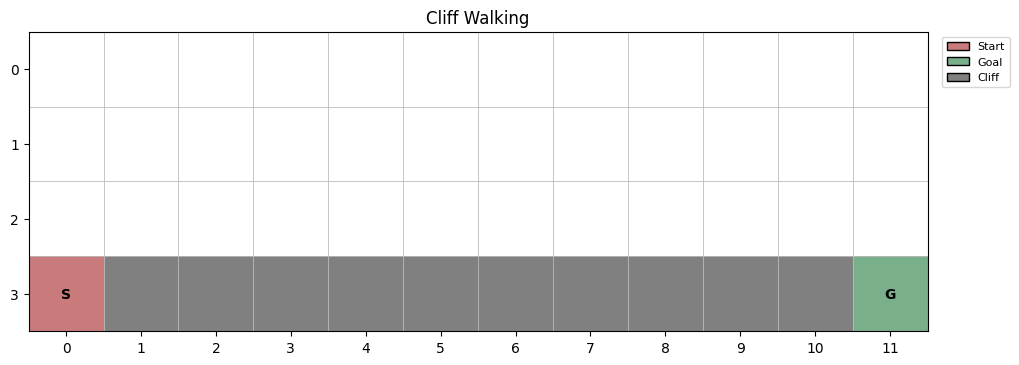

In [31]:
from draw import draw_cliffwalking

draw_cliffwalking(
    width=width,
    height=height,
    start=start,
    goal=goal,
    cliff=cliff,
    title="Cliff Walking"
)

plt.show()

## Gym environment 

In [32]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

In [33]:
class CliffWalkingEnv(gym.Env):
    def __init__(self, width, height, start, goal, cliff ):
        super().__init__()
        self.width = width
        self.height = height
        self.start = tuple(start)
        self.goal = tuple(goal)
        self.cliff = set(cliff)
        
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(width*height)
        
        self.moves = {
            0: (0, 1),
            1: (0,-1),
            2: (-1,0),
            3: (1, 0)
        }
    
    def reset(self,seed = None, options = None):
        super().reset(seed=seed)
        self.state = self.start
        
        return self._state_to_obs(self.state), {}

    
    def step(self, action):
        x,y = self.state
        terminated = False
        dx, dy = self.moves[action]
        
        truncated = False
        info = {}
        
        next_x = int(np.clip(x+dx, 0, self.width - 1))
        next_y = int(np.clip(y+dy, 0, self.height - 1))
        next_state = (next_x, next_y)
        reward = -1
        if next_state in self.cliff:
            reward = -100
            next_state = self.start
            
        elif next_state == self.goal:
            terminated = True
        
        self.state = next_state
            
        
        return self._state_to_obs(next_state), reward, terminated, truncated, info
    # helpers
    def _state_to_obs(self, position):
        x, y = position
        return y * self.width + x
    

In [34]:
env = CliffWalkingEnv(
    width=12,
    height=4,
    start=(0, 3),
    goal=(11, 3),
    cliff=[(x, 3) for x in range(1, 11)]
)

<Axes: >

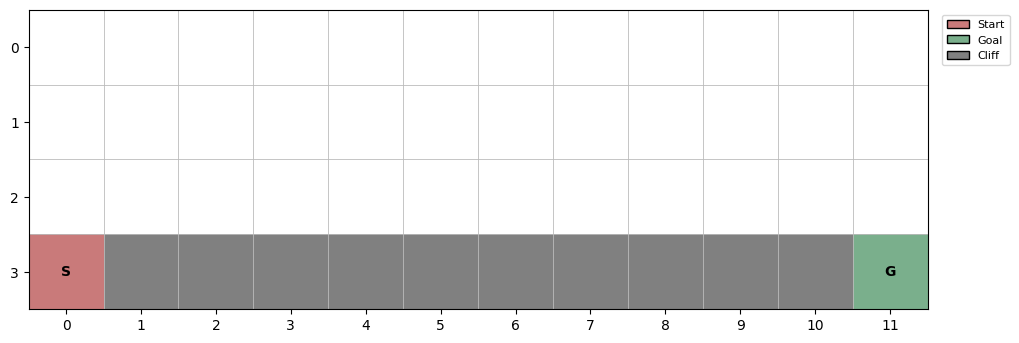

In [35]:
draw_cliffwalking(
    env.width,
    env.height,
    env.start,
    env.goal,
    env.cliff
)

In [36]:
## SARSA vs Q Learning

In [42]:
def epsilon_greedy(q, epsilon=0.1):
    if np.random.random() < epsilon:
        action = int(np.random.randint(len(q)))
    else:
        best_actions = np.flatnonzero(q == q.max())
        action = int(np.random.choice(best_actions))
        
    return int(action)

In [43]:
alpha = 0.5
gamma = 1.0
epsilon = 0.1
num_episodes = 500

In [44]:
def make_Q(env):
    return np.zeros((env.observation_space.n, env.action_space.n))

In [79]:
def run_sarsa(env, num_episodes, alpha=0.1, gamma=1.0, epsilon=0.1, seed=42):
    Q = make_Q(env)
    episode_returns = []

    for episode in range(num_episodes):
        steps = 0
        observation, info = env.reset(seed=seed if episode == 0 else None)
        action = epsilon_greedy(Q[observation], epsilon)

        G = 0
        terminated = False
        truncated = False

        while not terminated and not truncated and steps < 1000:
            S_next, reward, terminated, truncated, info = env.step(action)
            steps += 1
            G += reward

            if terminated or truncated:
                td_target = reward
            else:
                action_next = epsilon_greedy(Q[S_next], epsilon)
                td_target = reward + gamma * Q[S_next, action_next]

            td_error = td_target - Q[observation, action]
            Q[observation, action] += alpha * td_error

            if not terminated and not truncated:
                observation = S_next
                action = action_next
            if steps >= 100 and not terminated:
                truncated = True

        episode_returns.append(G)
        print(f"Episode {episode + 1}/{num_episodes} | Reward: {G}")

    return Q, episode_returns

In [80]:
Q_sarsa, returns_sarsa = run_sarsa(env, num_episodes=500)

Episode 1/500 | Reward: -496
Episode 2/500 | Reward: -298
Episode 3/500 | Reward: -397
Episode 4/500 | Reward: -199
Episode 5/500 | Reward: -397
Episode 6/500 | Reward: -100
Episode 7/500 | Reward: -298
Episode 8/500 | Reward: -100
Episode 9/500 | Reward: -100
Episode 10/500 | Reward: -199
Episode 11/500 | Reward: -100
Episode 12/500 | Reward: -298
Episode 13/500 | Reward: -135
Episode 14/500 | Reward: -100
Episode 15/500 | Reward: -298
Episode 16/500 | Reward: -100
Episode 17/500 | Reward: -69
Episode 18/500 | Reward: -93
Episode 19/500 | Reward: -199
Episode 20/500 | Reward: -199
Episode 21/500 | Reward: -33
Episode 22/500 | Reward: -100
Episode 23/500 | Reward: -100
Episode 24/500 | Reward: -91
Episode 25/500 | Reward: -84
Episode 26/500 | Reward: -100
Episode 27/500 | Reward: -77
Episode 28/500 | Reward: -100
Episode 29/500 | Reward: -100
Episode 30/500 | Reward: -92
Episode 31/500 | Reward: -54
Episode 32/500 | Reward: -199
Episode 33/500 | Reward: -57
Episode 34/500 | Reward: -45

In [81]:
def epsilon_greedy_policy(q, epsilon=0.1):
    n_actions = len(q)
    policy = np.ones(n_actions) * epsilon / n_actions

    best_actions = np.flatnonzero(q == q.max())
    policy[best_actions] += (1 - epsilon) / len(best_actions)

    return policy

In [82]:
def run_expected_sarsa(env, num_episodes, alpha=0.1, gamma=1.0, epsilon=0.1, seed=42):
    Q = make_Q(env)
    episode_returns = []

    for episode in range(num_episodes):
        observation, info = env.reset(seed=seed if episode == 0 else None)
        action = epsilon_greedy(Q[observation], epsilon)

        G = 0
        terminated = False
        truncated = False

        while not terminated and not truncated:
            S_next, reward, terminated, truncated, info = env.step(action)
            G += reward

            if terminated or truncated:
                td_target = reward
            else:
                action_next = epsilon_greedy(Q[S_next], epsilon)
                policy = epsilon_greedy_policy(Q[S_next], epsilon)
                expected_Q = np.sum(policy * Q[S_next])
                td_target = reward + gamma * expected_Q

            td_error = td_target - Q[observation, action]
            Q[observation, action] += alpha * td_error

            if not terminated and not truncated:
                observation = S_next
                action = action_next

        episode_returns.append(G)
        print(f"Episode {episode + 1}/{num_episodes} | Reward: {G}")

    return Q, episode_returns

In [83]:
Q_expected_sarsa, returns_expected_sarsa = run_expected_sarsa(env, num_episodes=500)

Episode 1/500 | Reward: -2424
Episode 2/500 | Reward: -164
Episode 3/500 | Reward: -296
Episode 4/500 | Reward: -48
Episode 5/500 | Reward: -281
Episode 6/500 | Reward: -120
Episode 7/500 | Reward: -299
Episode 8/500 | Reward: -148
Episode 9/500 | Reward: -89
Episode 10/500 | Reward: -308
Episode 11/500 | Reward: -79
Episode 12/500 | Reward: -133
Episode 13/500 | Reward: -147
Episode 14/500 | Reward: -232
Episode 15/500 | Reward: -235
Episode 16/500 | Reward: -729
Episode 17/500 | Reward: -151
Episode 18/500 | Reward: -92
Episode 19/500 | Reward: -64
Episode 20/500 | Reward: -269
Episode 21/500 | Reward: -43
Episode 22/500 | Reward: -90
Episode 23/500 | Reward: -95
Episode 24/500 | Reward: -105
Episode 25/500 | Reward: -262
Episode 26/500 | Reward: -123
Episode 27/500 | Reward: -209
Episode 28/500 | Reward: -91
Episode 29/500 | Reward: -50
Episode 30/500 | Reward: -89
Episode 31/500 | Reward: -60
Episode 32/500 | Reward: -295
Episode 33/500 | Reward: -184
Episode 34/500 | Reward: -91
E

In [84]:
def run_qlearning(env, num_episodes, alpha=0.1, gamma=1.0, epsilon=0.1, seed=42):
    Q = make_Q(env)
    episode_returns = []

    for episode in range(num_episodes):
        observation, info = env.reset(seed=seed if episode == 0 else None)
        action = epsilon_greedy(Q[observation], epsilon)

        G = 0
        terminated = False
        truncated = False

        while not terminated and not truncated:
            S_next, reward, terminated, truncated, info = env.step(action)
            G += reward

            if terminated or truncated:
                td_target = reward
            else:
                action_next = epsilon_greedy(Q[S_next], epsilon)
                td_target = reward + gamma * np.max(Q[S_next])

            td_error = td_target - Q[observation, action]
            Q[observation, action] += alpha * td_error

            if not terminated and not truncated:
                observation = S_next
                action = action_next

        episode_returns.append(G)
        print(f"Episode {episode + 1}/{num_episodes} | Reward: {G}")

    return Q, episode_returns

In [85]:
Q_qlearning, returns_qlearning = run_qlearning(env, num_episodes=500)

Episode 1/500 | Reward: -2973
Episode 2/500 | Reward: -148
Episode 3/500 | Reward: -670
Episode 4/500 | Reward: -318
Episode 5/500 | Reward: -576
Episode 6/500 | Reward: -441
Episode 7/500 | Reward: -120
Episode 8/500 | Reward: -74
Episode 9/500 | Reward: -484
Episode 10/500 | Reward: -227
Episode 11/500 | Reward: -83
Episode 12/500 | Reward: -335
Episode 13/500 | Reward: -363
Episode 14/500 | Reward: -74
Episode 15/500 | Reward: -75
Episode 16/500 | Reward: -464
Episode 17/500 | Reward: -375
Episode 18/500 | Reward: -236
Episode 19/500 | Reward: -65
Episode 20/500 | Reward: -64
Episode 21/500 | Reward: -215
Episode 22/500 | Reward: -353
Episode 23/500 | Reward: -59
Episode 24/500 | Reward: -53
Episode 25/500 | Reward: -215
Episode 26/500 | Reward: -55
Episode 27/500 | Reward: -76
Episode 28/500 | Reward: -187
Episode 29/500 | Reward: -80
Episode 30/500 | Reward: -264
Episode 31/500 | Reward: -276
Episode 32/500 | Reward: -65
Episode 33/500 | Reward: -70
Episode 34/500 | Reward: -317
E

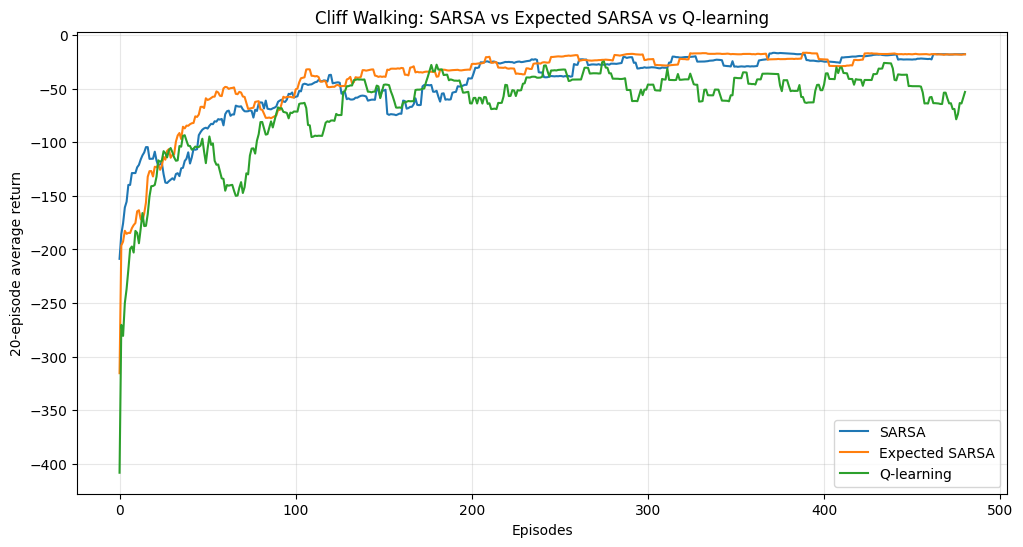

In [88]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(rewards, window=20):
    return np.convolve(rewards, np.ones(window) / window, mode="valid")

plt.figure(figsize=(12, 6))
plt.plot(moving_average(returns_sarsa), label="SARSA")
plt.plot(moving_average(returns_expected_sarsa), label="Expected SARSA")
plt.plot(moving_average(returns_qlearning), label="Q-learning")

plt.xlabel("Episodes")
plt.ylabel("20-episode average return")
plt.title("Cliff Walking: SARSA vs Expected SARSA vs Q-learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [89]:
print("SARSA:", np.mean(returns_sarsa[-100:]))
print("Expected SARSA:", np.mean(returns_expected_sarsa[-100:]))
print("Q-learning:", np.mean(returns_qlearning[-100:]))

SARSA: -20.54
Expected SARSA: -19.88
Q-learning: -48.19


In [90]:
def evaluate_greedy(env, Q, num_episodes=100, max_steps=100):
    returns = []
    successes = 0

    for episode in range(num_episodes):
        state, _ = env.reset()
        total_reward = 0

        for step in range(max_steps):
            # Purely greedy action; no exploration
            action = int(np.argmax(Q[state]))

            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward

            if terminated:
                successes += 1
                break

            if truncated:
                break

        returns.append(total_reward)

    return np.mean(returns), successes / num_episodes

In [92]:
for name, Q in [
    ("SARSA", Q_sarsa),
    ("Expected SARSA", Q_expected_sarsa),
    ("Q-learning", Q_qlearning),
]:
    avg_return, success_rate = evaluate_greedy(env, Q)

    print(
        f"{name:15s} | "
        f"Average return: {avg_return:7.2f} | "
        f"Success rate: {success_rate:.1%}"
    )

SARSA           | Average return:  -15.00 | Success rate: 100.0%
Expected SARSA  | Average return:  -15.00 | Success rate: 100.0%
Q-learning      | Average return:  -13.00 | Success rate: 100.0%
